Ghi chú ngày 2: học về pandas và eda
## Pandas 
- Pandas là thư viện python giúp đọc, lưu trữ, lọc, biến đổi, tổng hợp và phân tích dữ liệu dạng bảng, tương tự như excel nhưng có thể xử lý bằng code
=> Ví dụ: đọc file CSV chứa 100k đơn hàng, lọc đơn hàng lỗi, tính doanh thu theo tháng
## EDA - Exploratory Data Analysis
- Eda là quá trình phân tích khám phá dữ liệu nhằm hiểu dữ liệu có gì, phân phối ra sao, có bất thường không có những biến nào có thể liên quan đến nhau
=> Ví dụ: tìm hiểu vì sao doanh thu giảm, nhóm khách hàng nào mua nhiều nhất và sản phẩn nào bán chạy nhất

- Pandas thường được sử dụng để thực hiện EDA, kết với với các thư viện khác như numpy, matplotlib, seaborn

- 1 quy trình data science điển hình: thu thập dữ liệu => làm sạch dữ liệu => EDA => machine learning

In [2]:
## Đọc dữ liệu và kiểm tra giá trị thieu
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('train.csv')
print("Shape: ", df.shape)
print(df.dtypes)

missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
}).sort_values("missing_count", ascending=False)
missing

Shape:  (891, 12)
PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object


,missing_count,missing_pct
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22
PassengerId,0,0.00
Name,0,0.00
Pclass,0,0.00
Survived,0,0.00
Sex,0,0.00
Parch,0,0.00
SibSp,0,0.00


In [3]:
survival_rate = df["Survived"].mean()
print(f"Tỉ lệ sống sót: {survival_rate:.2%}")
df["Survived"].value_counts(normalize=True)

Tỉ lệ sống sót: 38.38%


Survived
0    0.616162
1    0.383838
Name: proportion, dtype: float64

Sex
female    0.742
male      0.189
Name: Survived, dtype: float64 

Pclass
1    0.630
2    0.473
3    0.242
Name: Survived, dtype: float64 

Embarked
C    0.554
Q    0.390
S    0.337
Name: Survived, dtype: float64 



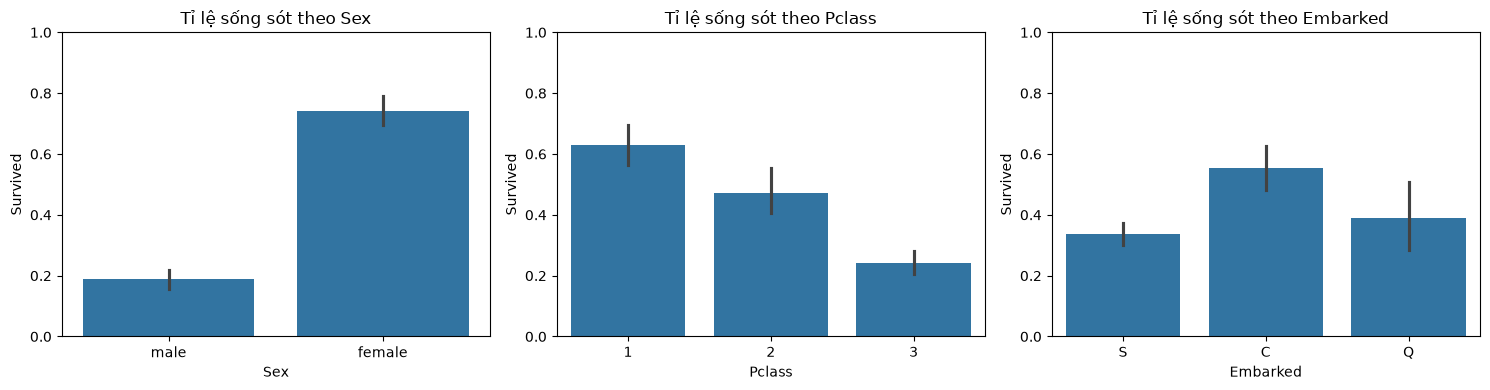

In [4]:
cols = ["Sex", "Pclass", "Embarked"]
for col in cols:
    print(df.groupby(col)["Survived"].mean().round(3), "\n")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, cols):
    sns.barplot(data=df, x=col, y="Survived", ax=ax)
    ax.set_title(f"Tỉ lệ sống sót theo {col}")
    ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

In [5]:
pivot = df.pivot_table(index="Sex", columns="Pclass", values="Survived", aggfunc="mean")
print(pivot.round(3))

stacked = pivot.stack()
print("Cao nhất:", stacked.idxmax(), round(stacked.max(), 3))
print("Thấp nhất:", stacked.idxmin(), round(stacked.min(), 3))


Pclass      1      2      3
Sex                        
female  0.968  0.921  0.500
male    0.369  0.157  0.135
Cao nhất: ('female', np.int64(1)) 0.968
Thấp nhất: ('male', np.int64(3)) 0.135


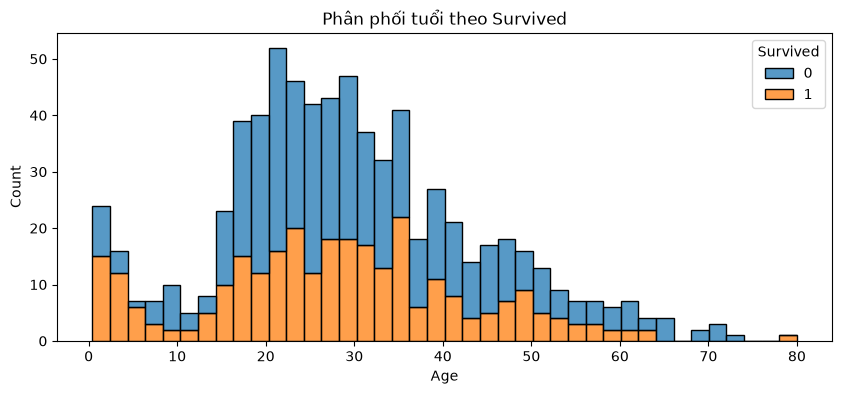

Tỉ lệ sống của trẻ ≤ 12 tuổi: 0.58


In [6]:
plt.figure(figsize=(10, 4))
sns.histplot(data=df, x="Age", hue="Survived", bins=40, multiple="stack")
plt.title("Phân phối tuổi theo Survived")
plt.show()

print("Tỉ lệ sống của trẻ ≤ 12 tuổi:", round(df.loc[df["Age"] <= 12, "Survived"].mean(), 3))


In [7]:
df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[0, 12, 18, 35, 60, 100],
    labels=["Child", "Teen", "YoungAdult", "Adult", "Senior"],
)
df.groupby("AgeGroup", observed=True)["Survived"].agg(["mean", "count"]).round(3)


,mean,count
AgeGroup,,
Child,0.580,69
Teen,0.429,70
YoungAdult,0.383,358
Adult,0.400,195
Senior,0.227,22


        count   mean    std  min    25%    50%   75%     max
Pclass                                                      
1       216.0  84.15  78.38  0.0  30.92  60.29  93.5  512.33
2       184.0  20.66  13.42  0.0  13.00  14.25  26.0   73.50
3       491.0  13.68  11.78  0.0   7.75   8.05  15.5   69.55


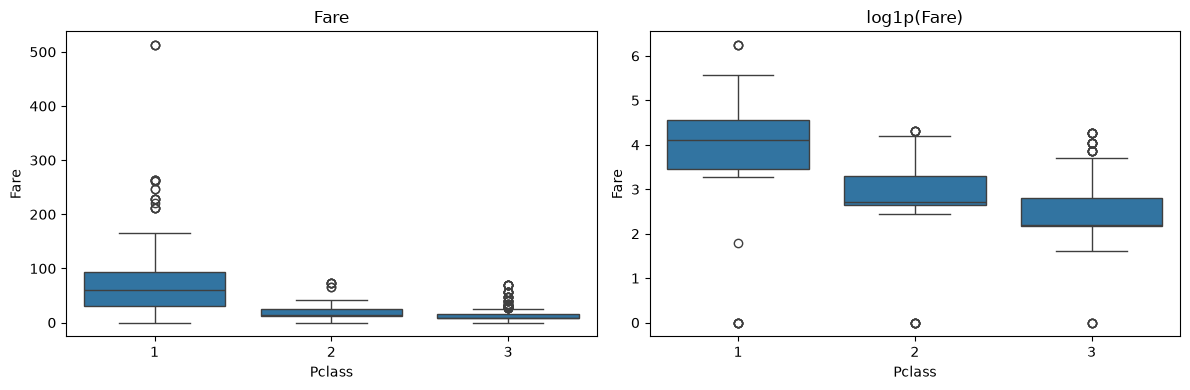

In [8]:
print(df.groupby("Pclass")["Fare"].describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x="Pclass", y="Fare", ax=axes[0])
axes[0].set_title("Fare")
sns.boxplot(x=df["Pclass"], y=np.log1p(df["Fare"]), ax=axes[1])
axes[1].set_title("log1p(Fare)")
plt.tight_layout()
plt.show()


             mean  count
FamilySize              
1           0.304    537
2           0.553    161
3           0.578    102
4           0.724     29
5           0.200     15
6           0.136     22
7           0.333     12
8           0.000      6
11          0.000      7
IsAlone
0    0.506
1    0.304
Name: Survived, dtype: float64


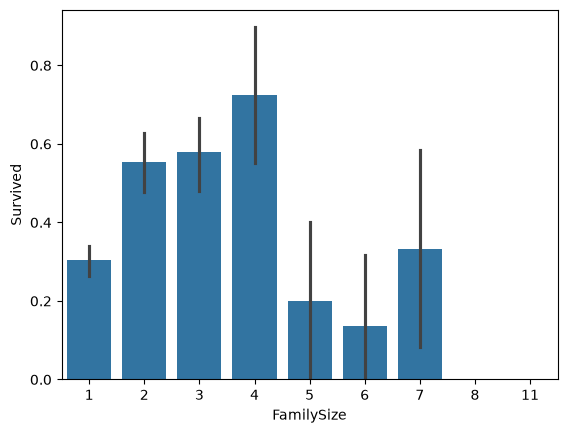

In [9]:
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
df["IsAlone"] = (df["FamilySize"] == 1).astype(int)

print(df.groupby("FamilySize")["Survived"].agg(["mean", "count"]).round(3))
print(df.groupby("IsAlone")["Survived"].mean().round(3))

sns.barplot(data=df, x="FamilySize", y="Survived")
plt.show()


In [10]:
df["Title"] = df["Name"].str.extract(r",\s*([^\.]+)\.", expand=False)
df["Title"] = df["Title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})

counts = df["Title"].value_counts()
rare_titles = counts[counts < 10].index
df["Title"] = df["Title"].where(~df["Title"].isin(rare_titles), "Rare")

df.groupby("Title")["Survived"].agg(["mean", "count"]).sort_values("mean", ascending=False).round(3)


,mean,count
Title,,
Mrs,0.794,126
Miss,0.703,185
Master,0.575,40
Rare,0.348,23
Mr,0.157,517


In [11]:
print("Trước:", df["Age"].isna().sum())
df["Age"] = df["Age"].fillna(df.groupby("Title")["Age"].transform("median"))
print("Sau:", df["Age"].isna().sum())

df.groupby("Title")["Age"].median()


Trước: 177
Sau: 0


Title
Master     3.5
Miss      21.0
Mr        30.0
Mrs       35.0
Rare      48.5
Name: Age, dtype: float64

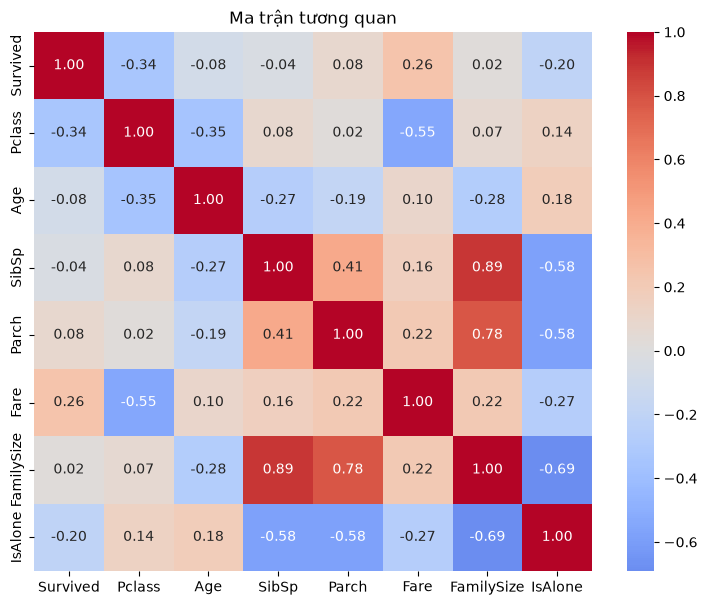

Pclass        0.338481
Fare          0.257307
IsAlone       0.203367
Parch         0.081629
Age           0.078931
SibSp         0.035322
FamilySize    0.016639
Name: Survived, dtype: float64

In [12]:
num = df.select_dtypes("number").drop(columns="PassengerId")
corr = num.corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Ma trận tương quan")
plt.show()

corr["Survived"].drop("Survived").abs().sort_values(ascending=False)


In [13]:
print(f"Cabin thiếu: {df['Cabin'].isna().mean():.2%}")

df["HasCabin"] = df["Cabin"].notna().astype(int)
print(df.groupby("HasCabin")["Survived"].agg(["mean", "count"]).round(3))
pd.crosstab(df["Pclass"], df["HasCabin"])


Cabin thiếu: 77.10%
           mean  count
HasCabin              
0         0.300    687
1         0.667    204


HasCabin,0,1
Pclass,,
1,40,176
2,168,16
3,479,12


## Tổng kết

### 5 nhận định quan trọng
1. **Giới tính**: nữ sống 74.2%, nam chỉ 18.9%.
2. **Hạng vé**: hạng 1 63% so với hạng 3 24.2%; nữ hạng 1 cao nhất (96.8%), nam hạng 3 thấp nhất (13.5%).
3. **Title**: 3.5
4. **Gia đình**: FamilySize 2–4 sống 61.64%, đi một mình 30.4%, gia đình ≥ 5 chỉ 16.11%.
5. **Cabin**: thiếu 77.1%; có Cabin sống 30% so với 66.7%.